# Evidence Novelty

Repeated range observations are not necessarily independent. Observations acquired from similar sensor states may contain substantially redundant information and should therefore not increase evidence concentration at the same rate as observations acquired from novel states.

This example defines observation novelty using Mahalanobis distance in a lifted spatiotemporal acquisition space.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

from beta_evidence_field import (OccupancyField, OccupancyObservation, OccupancyPrior)
from tools.plotting      import configure_plots, plot_observation_2d, plot_field_2d

c:\Code\beta-evidence-fields\.pixi\envs\default\lib\python\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
field = OccupancyField.from_yaml("../config/example_2d_config.yaml")

reference = OccupancyObservation(origin    = np.array([0.0, 0.0]),
                                 direction = np.array([1.0, 0.0]),
                                 range     = 3.0,
                                 returned  = True,
                                 time      = 0.0)

field.clear()
field.add([reference])

[OccupancyObservation(origin=array([0., 0.]), direction=array([1., 0.]), range=3.0, returned=True, time=0.0, evidence_weight=1.0)]

In [3]:
angles = np.linspace(0.0, np.pi/2.0, 200)

novelty = []


for angle in angles:

    field.clear()

    field.add([
        OccupancyObservation(
            origin    = np.array([0.0, 0.0]),
            direction = np.array([1.0, 0.0]),
            range     = 3.0,
            returned  = True,
            time      = 0.0,
        )
    ])

    observation = OccupancyObservation(
        origin    = np.array([0.0, 0.0]),
        direction = np.array([np.cos(angle), np.sin(angle)]),
        range     = 3.0/np.cos(angle),
        returned  = True,
        time      = 0.0,
    )

    field.add([observation])

    novelty.append(observation.novelty)

(0.0, 1.0)

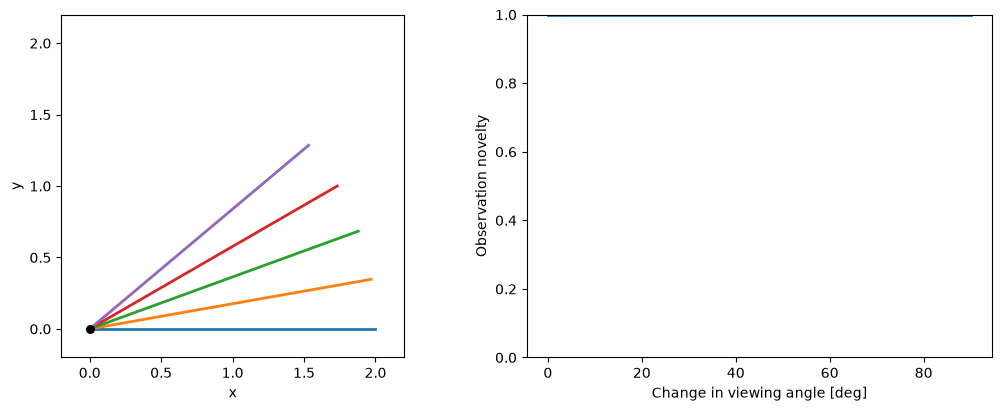

In [4]:
fig, axes = plt.subplots(
    1, 2,
    figsize = (10, 4),
    constrained_layout = True,
)


# Viewing geometry

origin = np.array([0.0, 0.0])

example_angles = np.radians([
    0.0,
    10.0,
    20.0,
    30.0,
    40.0,
])

for angle in example_angles:

    direction = np.array([
        np.cos(angle),
        np.sin(angle),
    ])

    endpoint = origin + 2.0*direction

    axes[0].plot(
        [origin[0], endpoint[0]],
        [origin[1], endpoint[1]],
        linewidth = 2,
    )

axes[0].scatter(
    origin[0],
    origin[1],
    color = "black",
    s     = 30,
    zorder = 3,
)

axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].set_aspect("equal")

axes[0].set_xlim(-0.2, 2.2)
axes[0].set_ylim(-0.2, 2.2)


# Novelty

axes[1].plot(
    np.degrees(angles),
    novelty,
    linewidth = 2,
)

axes[1].set_xlabel("Change in viewing angle [deg]")
axes[1].set_ylabel("Observation novelty")
axes[1].set_ylim(0.0, 1.0)